
DESCRIPTIVE STATISTICS
     count         mean          std  min     25%     50%     75%      max
y18  256.0    47.085938    62.253124  0.0    13.0    23.5    51.0    416.0
y19  256.0   105.402344   267.893684  0.0     3.0     9.0    50.0   2851.0
y20  256.0  5752.164062  4772.556242  0.0  2233.5  5214.0  8280.5  26768.0

ANNUAL DISEASE TOTALS
   Year   y18    y19     y20
0  2017  2367    900  262525
1  2018  2362    976  410258
2  2019  3895  24321  506433
3  2020  3430    786  293338


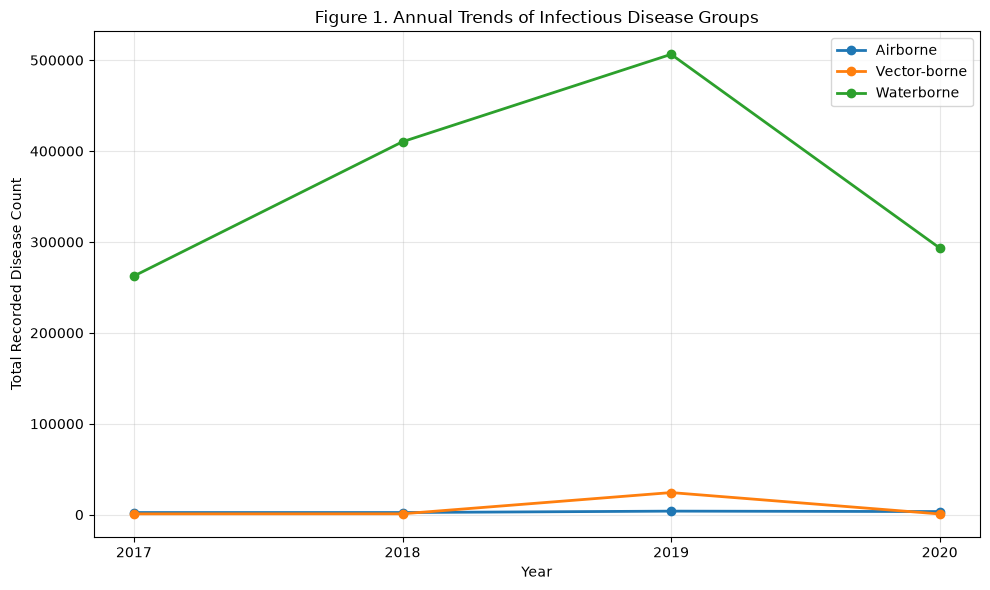

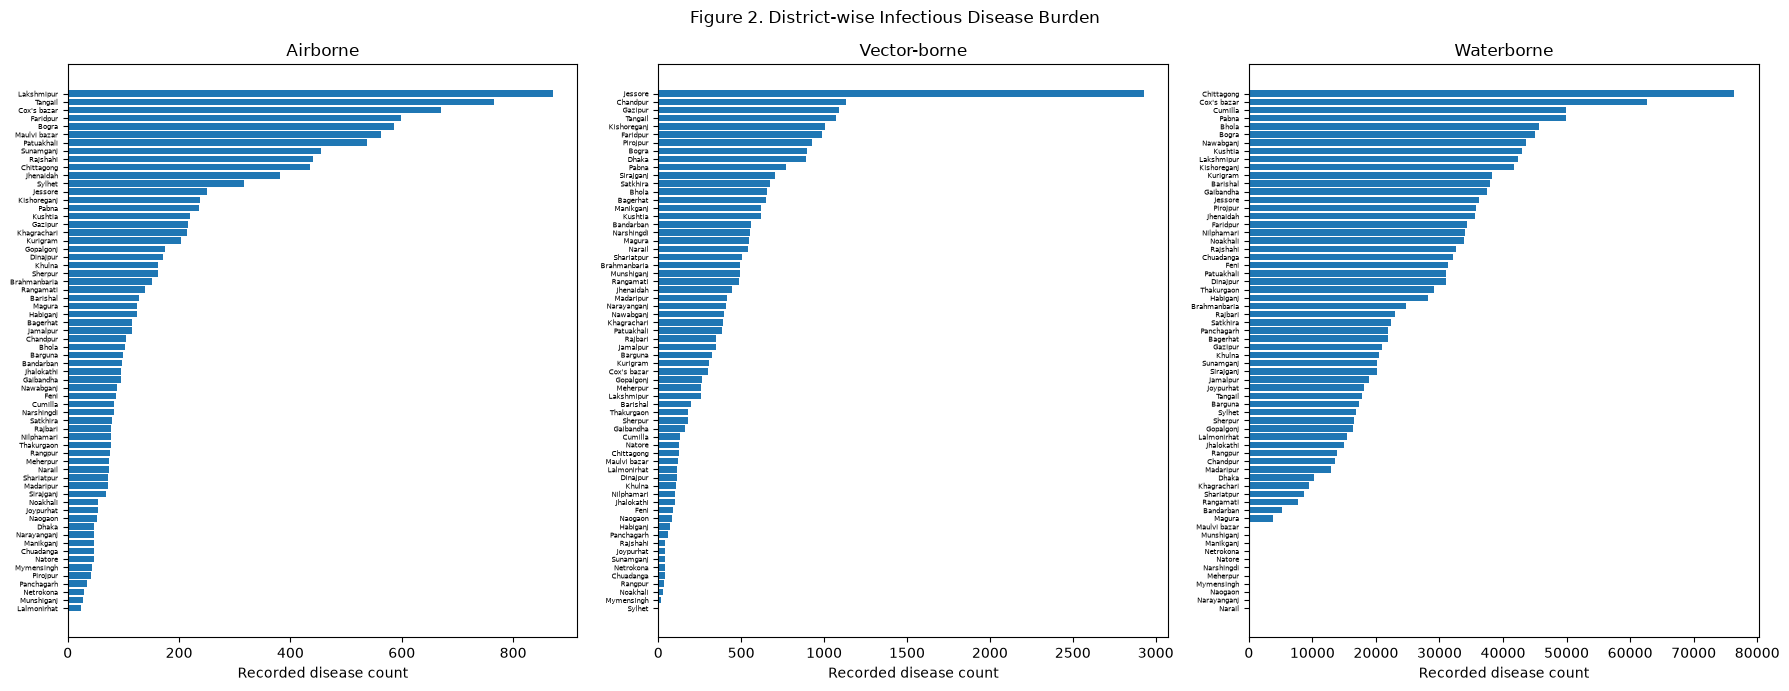

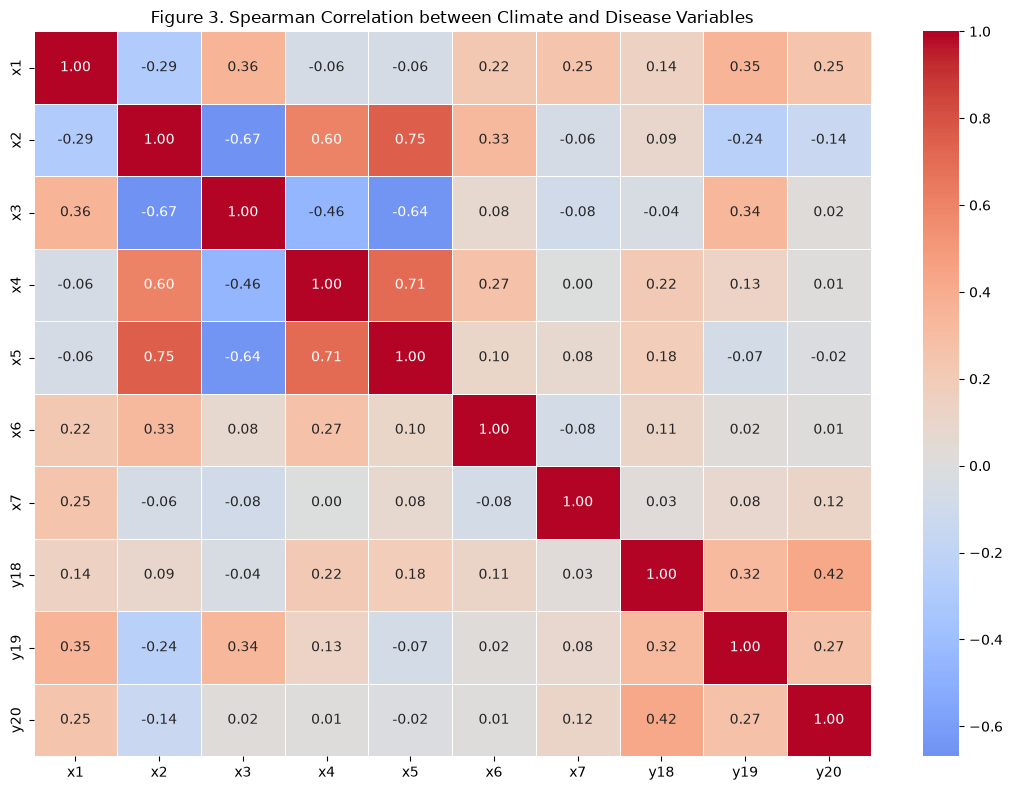


GLOBAL MORAN'S I
  Disease group  Year   Moran I  Permutation Z  Permutation P
0      Airborne  2020 -0.108356      -1.242286          0.132
1  Vector-borne  2020 -0.017113       0.022247          0.822
2    Waterborne  2020 -0.012739       0.043024          0.879


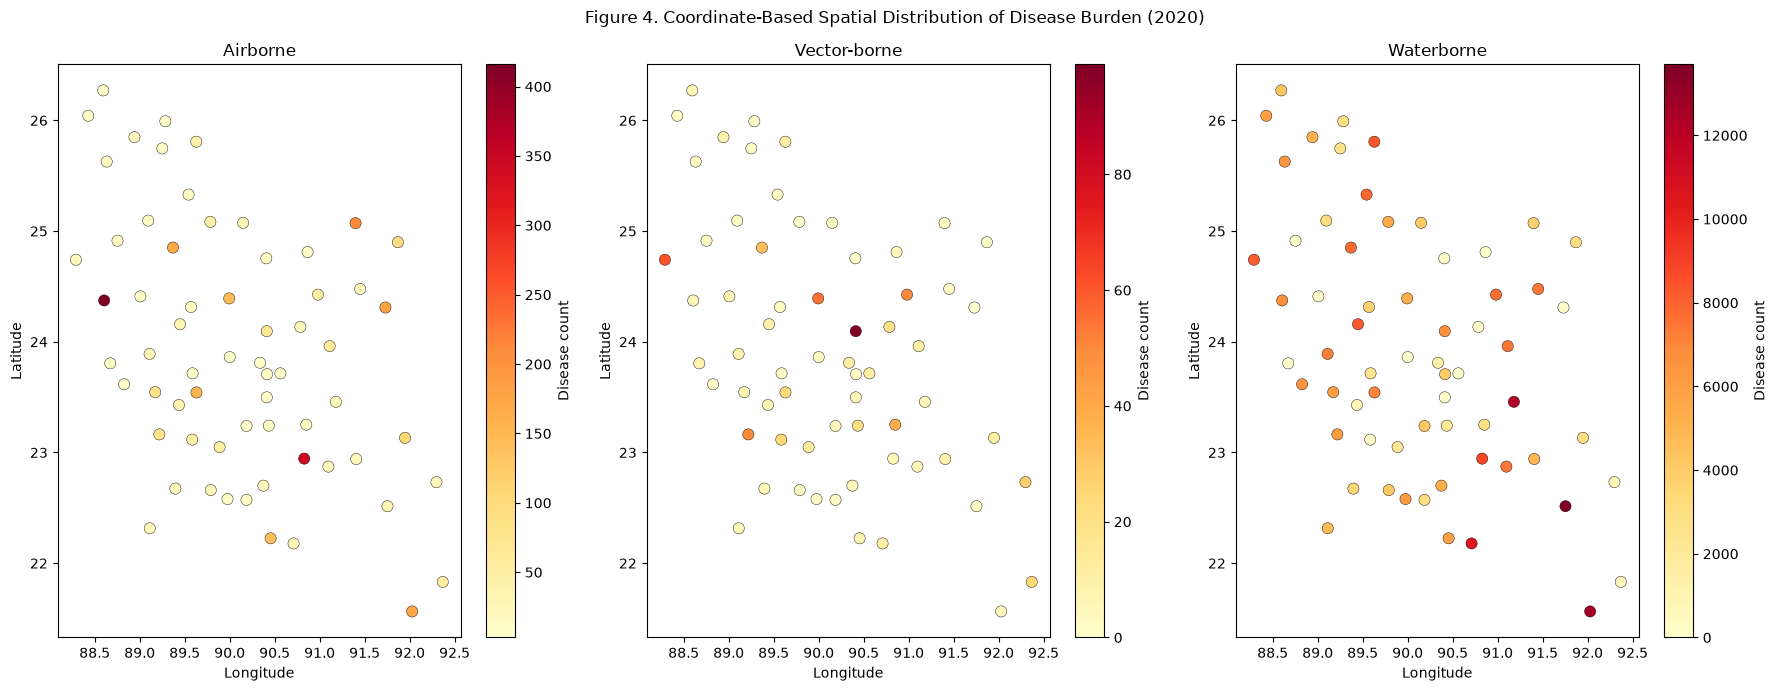

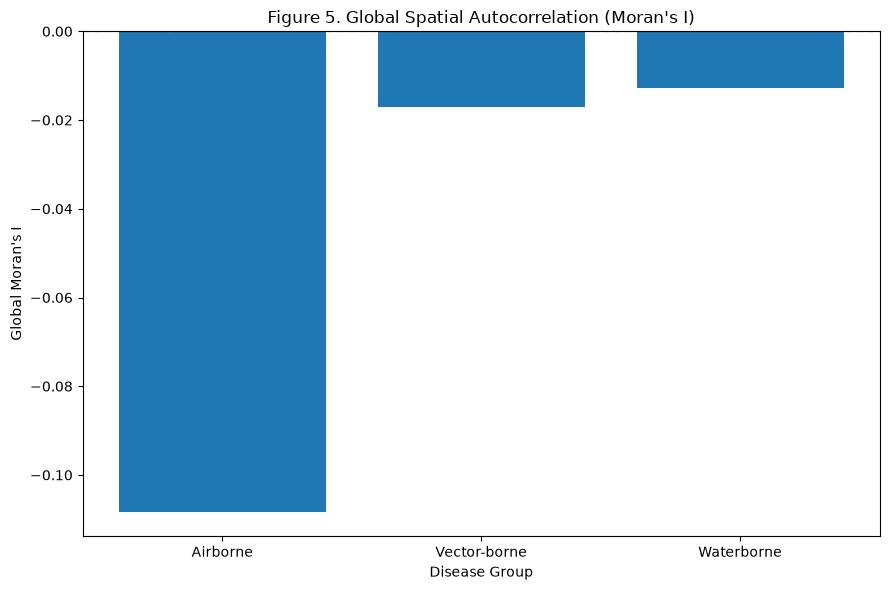

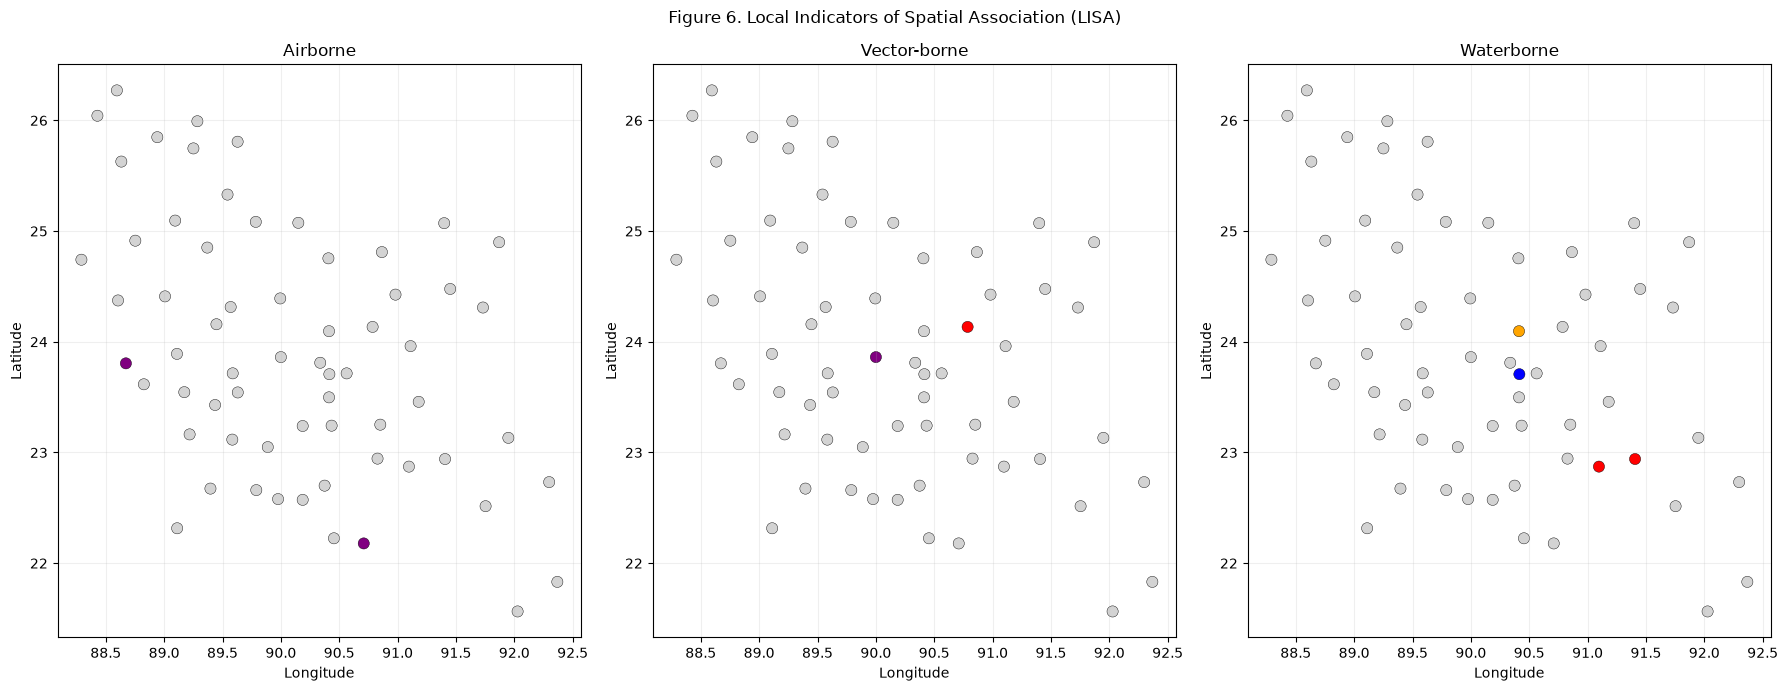

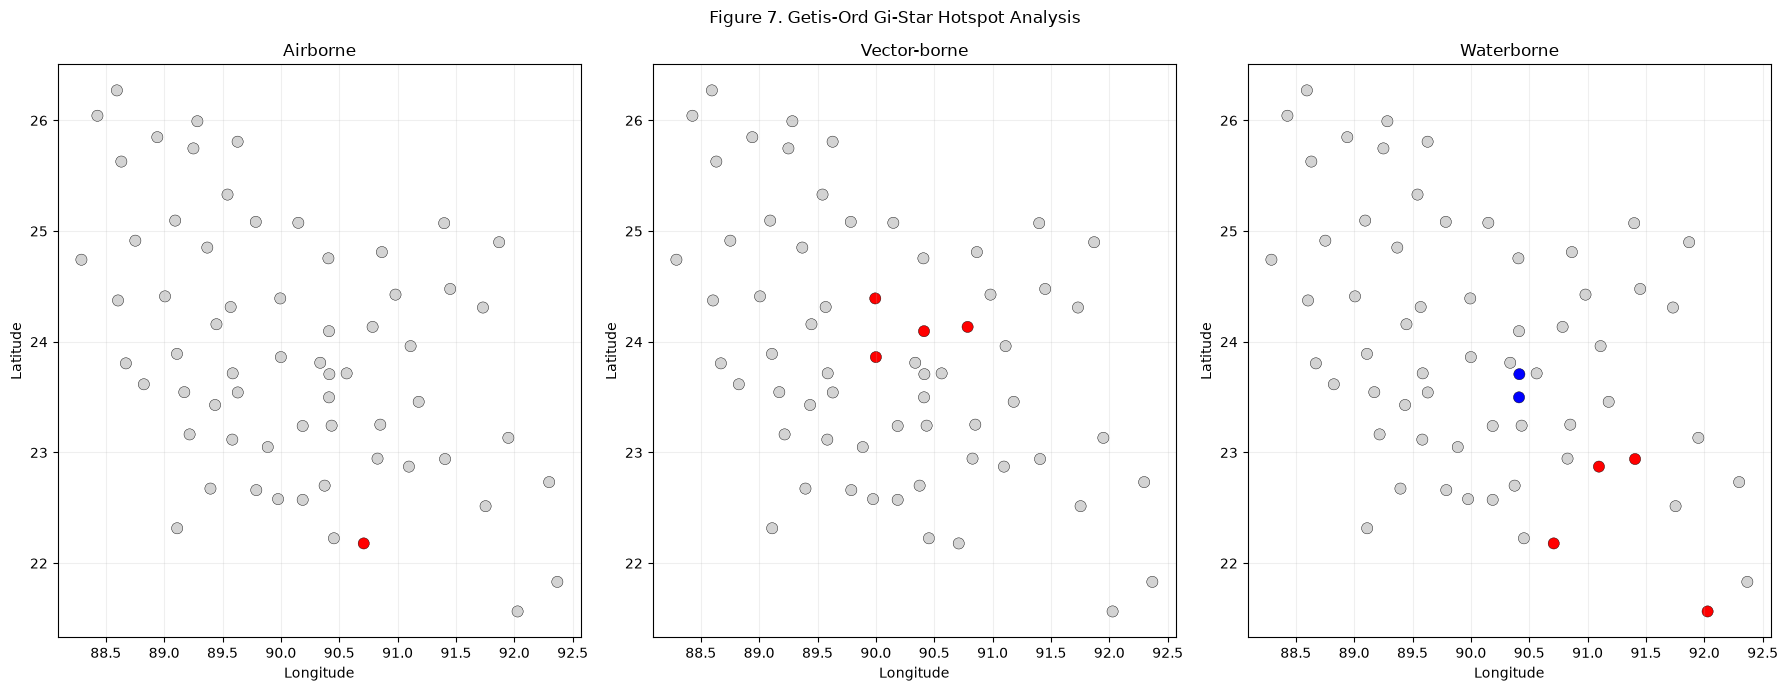

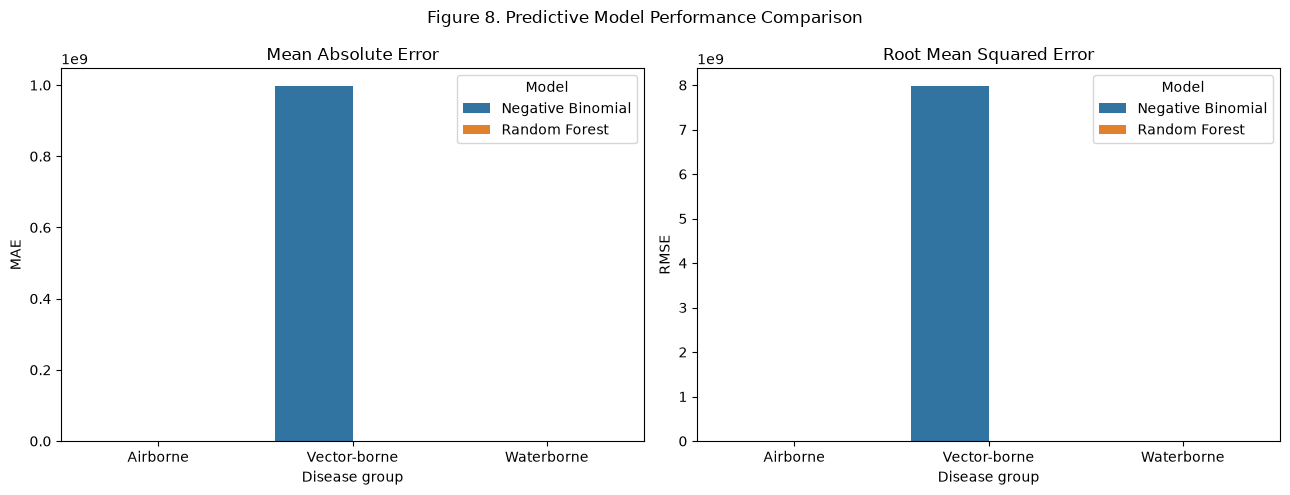

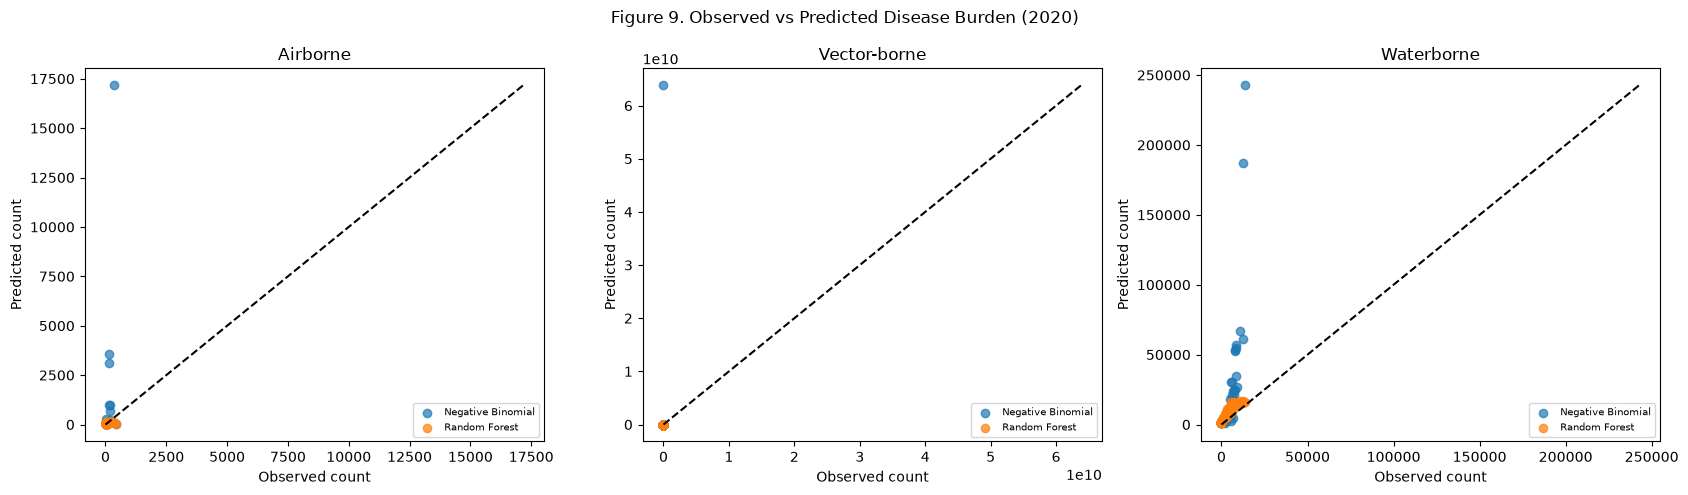

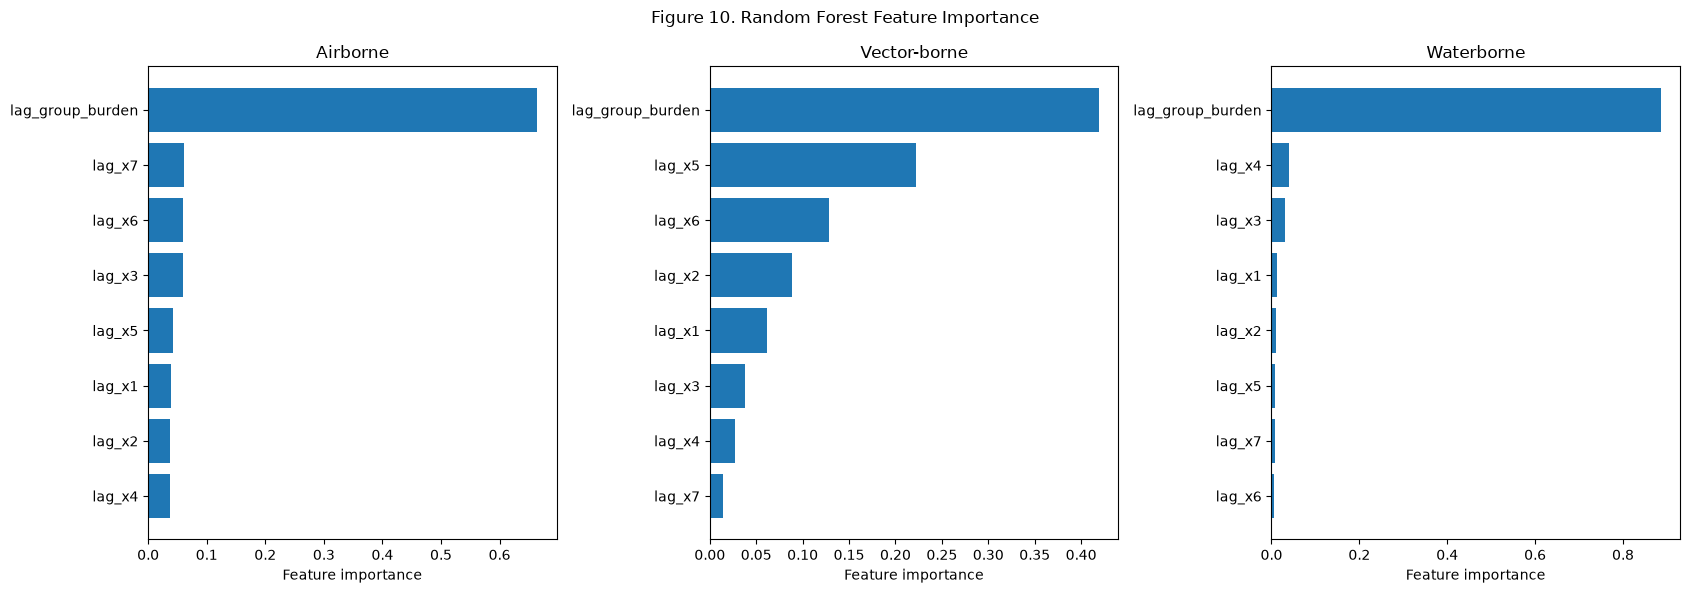


BANGLADESH INFECTIOUS DISEASE ANALYSIS COMPLETED

GLOBAL MORAN'S I RESULTS
  Disease group  Year   Moran I  Permutation Z  Permutation P
0      Airborne  2020 -0.108356      -1.242286          0.132
1  Vector-borne  2020 -0.017113       0.022247          0.822
2    Waterborne  2020 -0.012739       0.043024          0.879

PREDICTIVE MODEL PERFORMANCE
  Disease group              Model  Training observations  \
0      Airborne  Negative Binomial                    128   
1      Airborne      Random Forest                    128   
2  Vector-borne  Negative Binomial                    128   
3  Vector-borne      Random Forest                    128   
4    Waterborne  Negative Binomial                    128   
5    Waterborne      Random Forest                    128   

   Testing observations           MAE          RMSE  
0                    64  4.296725e+02  2.184198e+03  
1                    64  3.907917e+01  6.835807e+01  
2                    64  9.972106e+08  7.977376e+09  
3 

In [1]:
# ================================================================
# RESEARCH:
# Spatial Epidemiology and Predictive Modelling of Infectious
# Diseases in Bangladesh: A District-Level Spatio-Temporal Analysis
#
# Study period: 2017-2020
# Spatial units: 64 districts
# Prediction targets: Airborne, Vector-borne, Waterborne
#
# All tables, statistical results and figures will be saved.
# ================================================================


# 1. IMPORT LIBRARIES
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial import cKDTree
from scipy.stats import spearmanr

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

import statsmodels.api as sm

warnings.filterwarnings("ignore")

np.random.seed(42)

# ================================================================
# 2. FILE PATHS AND SETTINGS
# ================================================================

FILE = "Infectious Disease Data (1).xlsx"

OUTPUT = "Bangladesh_Infectious_Disease_Results"

FIG_DIR = os.path.join(OUTPUT, "Figures")
TABLE_DIR = os.path.join(OUTPUT, "Tables")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

SPATIAL_YEAR = 2020
PERMUTATIONS = 999

# ================================================================
# 3. LOAD DATA
# ================================================================

df = pd.read_excel(FILE)

df.columns = df.columns.astype(str).str.strip()

df = df.rename(columns={
    "Distirct": "District",
    "district": "District",
    "year": "Year",
    "latitude": "Latitude",
    "longitude": "Longitude"
})

required_columns = [
    "District", "Year", "Latitude", "Longitude",
    "y18", "y19", "y20",
    "x1", "x2", "x3", "x4", "x5", "x6", "x7"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

df = df.sort_values(["District", "Year"]).reset_index(drop=True)

# Disease groups

groups = {
    "Airborne": {
        "target": "y18",
        "components": ["y1", "y2", "y3", "y4", "y5", "y6"]
    },

    "Vector-borne": {
        "target": "y19",
        "components": ["y7", "y8", "y9", "y10", "y11", "y12"]
    },

    "Waterborne": {
        "target": "y20",
        "components": ["y13", "y14", "y15", "y16", "y17"]
    }
}

climate_vars = [
    "x1", "x2", "x3", "x4", "x5", "x6", "x7"
]

targets = ["y18", "y19", "y20"]

group_names = list(groups.keys())

# ================================================================
# 4. DATA VALIDATION AND CLEANING
# ================================================================

validation = []

validation.append(["Total observations", len(df)])
validation.append(["Number of districts", df["District"].nunique()])
validation.append(["Number of years", df["Year"].nunique()])
validation.append(["First year", df["Year"].min()])
validation.append(["Last year", df["Year"].max()])

validation.append([
    "Duplicate district-year records",
    df.duplicated(["District", "Year"]).sum()
])

validation.append([
    "Total missing values",
    df.isna().sum().sum()
])

for col in df.columns:

    validation.append([
        f"Missing values in {col}",
        df[col].isna().sum()
    ])

# Coordinate consistency

coord_check = df.groupby("District")[
    ["Latitude", "Longitude"]
].nunique()

inconsistent_coordinates = (
    (coord_check > 1).any(axis=1).sum()
)

validation.append([
    "Districts with inconsistent coordinates",
    inconsistent_coordinates
])

# Check aggregate totals against component indicators

for group, info in groups.items():

    target = info["target"]
    components = info["components"]

    if all(c in df.columns for c in components):

        valid = df[components + [target]].notna().all(axis=1)

        component_sum = df.loc[valid, components].sum(axis=1)

        difference = (
            component_sum - df.loc[valid, target]
        ).abs()

        validation.append([
            f"{group} aggregate mismatches",
            (difference > 0.001).sum()
        ])

pd.DataFrame(
    validation,
    columns=["Validation", "Result"]
).to_csv(
    os.path.join(TABLE_DIR, "01_Data_Validation.csv"),
    index=False
)

# Save cleaned copy without altering original data

df.to_csv(
    os.path.join(TABLE_DIR, "02_Analysis_Dataset.csv"),
    index=False
)

# ================================================================
# 5. DESCRIPTIVE STATISTICAL ANALYSIS
# ================================================================

descriptive = df[targets].describe().T

descriptive.to_csv(
    os.path.join(TABLE_DIR, "03_Descriptive_Statistics.csv")
)

annual = df.groupby("Year")[targets].sum().reset_index()

annual.to_csv(
    os.path.join(TABLE_DIR, "04_Annual_Disease_Totals.csv"),
    index=False
)

district_summary = df.groupby("District")[targets].sum()

district_summary.to_csv(
    os.path.join(TABLE_DIR, "05_District_Disease_Summary.csv")
)

print("\nDESCRIPTIVE STATISTICS")
print(descriptive)

print("\nANNUAL DISEASE TOTALS")
print(annual)

# ================================================================
# 6. FIGURE 1: ANNUAL DISEASE TRENDS
# ================================================================

plt.figure(figsize=(10, 6))

for group, info in groups.items():

    plt.plot(
        annual["Year"],
        annual[info["target"]],
        marker="o",
        linewidth=2,
        label=group
    )

plt.title("Figure 1. Annual Trends of Infectious Disease Groups")

plt.xlabel("Year")
plt.ylabel("Total Recorded Disease Count")

plt.xticks(annual["Year"])

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_01_Annual_Trends.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 7. FIGURE 2: DISTRICT-WISE DISEASE BURDEN
# ================================================================

district_plot = (
    df.groupby("District")[targets]
    .sum()
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (group, info) in zip(axes, groups.items()):

    target = info["target"]

    ordered = district_plot.sort_values(target)

    ax.barh(
        ordered["District"],
        ordered[target]
    )

    ax.set_title(group)
    ax.set_xlabel("Recorded disease count")
    ax.tick_params(axis="y", labelsize=5)

plt.suptitle(
    "Figure 2. District-wise Infectious Disease Burden"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_02_District_Burden.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 8. CLIMATE-DISEASE CORRELATION
# ================================================================

correlation_rows = []

for target in targets:

    for climate in climate_vars:

        temp = df[[target, climate]].dropna()

        rho, p_value = spearmanr(
            temp[climate],
            temp[target]
        )

        correlation_rows.append([
            target,
            climate,
            rho,
            p_value,
            len(temp)
        ])

correlation_df = pd.DataFrame(
    correlation_rows,
    columns=[
        "Disease group",
        "Climate variable",
        "Spearman correlation",
        "P-value",
        "N"
    ]
)

correlation_df.to_csv(
    os.path.join(TABLE_DIR, "06_Climate_Disease_Correlation.csv"),
    index=False
)

# Correlation matrix

corr_matrix = df[climate_vars + targets].corr(
    method="spearman"
)

corr_matrix.to_csv(
    os.path.join(TABLE_DIR, "07_Correlation_Matrix.csv")
)

# ================================================================
# 9. FIGURE 3: CLIMATE-DISEASE CORRELATION HEATMAP
# ================================================================

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Figure 3. Spearman Correlation between Climate and Disease Variables"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_03_Correlation_Heatmap.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 10. SPATIAL COORDINATES AND KNN WEIGHTS
# ================================================================

district_coords = (
    df[["District", "Latitude", "Longitude"]]
    .drop_duplicates()
    .sort_values("District")
    .reset_index(drop=True)
)

if district_coords["District"].duplicated().any():

    raise ValueError(
        "A district has multiple coordinate pairs."
    )

if district_coords[["Latitude", "Longitude"]].isna().any().any():

    raise ValueError(
        "Missing spatial coordinates. Check the original dataset."
    )

n = len(district_coords)

lat0 = np.deg2rad(
    district_coords["Latitude"].mean()
)

xy = np.column_stack([
    district_coords["Longitude"].to_numpy()
    * 111.32 * np.cos(lat0),

    district_coords["Latitude"].to_numpy()
    * 110.57
])

# Four nearest neighbours

tree = cKDTree(xy)

distances, indices = tree.query(
    xy,
    k=5
)

W_binary = np.zeros((n, n))

for i in range(n):

    W_binary[i, indices[i, 1:]] = 1

# Symmetrize the neighbourhood matrix

W_binary = np.maximum(
    W_binary,
    W_binary.T
)

# Row standardization

row_sums = W_binary.sum(axis=1)

W = np.divide(
    W_binary,
    row_sums[:, None],
    out=np.zeros_like(W_binary),
    where=row_sums[:, None] != 0
)

# Save spatial neighbours

neighbours = []

for i, district in enumerate(district_coords["District"]):

    for j in np.where(W_binary[i] > 0)[0]:

        neighbours.append([
            district,
            district_coords.loc[j, "District"]
        ])

pd.DataFrame(
    neighbours,
    columns=["District", "Neighbour"]
).to_csv(
    os.path.join(TABLE_DIR, "08_Spatial_Neighbours.csv"),
    index=False
)

# ================================================================
# 11. SPATIAL STATISTICAL FUNCTIONS
# ================================================================

def global_moran(values, W, permutations=999, seed=42):

    x = np.asarray(values, dtype=float)

    z = x - x.mean()

    denominator = np.sum(z ** 2)

    if denominator == 0:

        return np.nan, np.nan, np.nan

    n = len(x)

    s0 = W.sum()

    observed = (
        n / s0
    ) * (
        z @ W @ z
    ) / denominator

    rng = np.random.default_rng(seed)

    simulated = []

    for _ in range(permutations):

        zp = rng.permutation(z)

        simulated.append(
            (n / s0) * (zp @ W @ zp) / denominator
        )

    simulated = np.asarray(simulated)

    p_value = (
        1 + np.sum(np.abs(simulated) >= abs(observed))
    ) / (permutations + 1)

    z_score = (
        observed - simulated.mean()
    ) / simulated.std(ddof=1)

    return observed, z_score, p_value


def local_moran(values, W, permutations=999, seed=42):

    x = np.asarray(values, dtype=float)

    sd = x.std()

    if sd == 0:

        return (
            np.zeros(len(x)),
            np.ones(len(x)),
            np.array(["Not significant"] * len(x))
        )

    z = (x - x.mean()) / sd

    spatial_lag = W @ z

    local_i = z * spatial_lag

    rng = np.random.default_rng(seed)

    p_values = np.ones(len(x))

    for i in range(len(x)):

        neighbours = np.where(W[i] > 0)[0]

        if len(neighbours) == 0:
            continue

        pool = np.delete(z, i)

        observed_abs = abs(local_i[i])

        simulated = []

        for _ in range(permutations):

            sampled = rng.choice(
                pool,
                size=len(neighbours),
                replace=False
            )

            simulated.append(
                abs(z[i] * sampled.mean())
            )

        p_values[i] = (
            1 + np.sum(np.array(simulated) >= observed_abs)
        ) / (permutations + 1)

    clusters = np.full(
        len(x),
        "Not significant",
        dtype=object
    )

    sig = p_values < 0.05

    clusters[sig & (z > 0) & (spatial_lag > 0)] = "High-High"

    clusters[sig & (z < 0) & (spatial_lag < 0)] = "Low-Low"

    clusters[sig & (z > 0) & (spatial_lag < 0)] = "High-Low"

    clusters[sig & (z < 0) & (spatial_lag > 0)] = "Low-High"

    return local_i, p_values, clusters


def getis_gistar(values, W_binary, permutations=999, seed=42):

    x = np.asarray(values, dtype=float)

    # Include the focal district in Gi-star

    B = W_binary.copy()

    np.fill_diagonal(B, 1)

    observed = B @ x

    rng = np.random.default_rng(seed)

    simulated = np.array([
        B @ rng.permutation(x)
        for _ in range(permutations)
    ])

    sim_mean = simulated.mean(axis=0)

    sim_sd = simulated.std(axis=0, ddof=1)

    z_scores = np.divide(
        observed - sim_mean,
        sim_sd,
        out=np.zeros_like(observed),
        where=sim_sd > 0
    )

    p_values = (
        1 + np.sum(
            np.abs(simulated - sim_mean)
            >= np.abs(observed - sim_mean),
            axis=0
        )
    ) / (permutations + 1)

    classification = np.full(
        len(x),
        "Not significant",
        dtype=object
    )

    classification[
        (z_scores > 0) & (p_values < 0.05)
    ] = "Hotspot"

    classification[
        (z_scores < 0) & (p_values < 0.05)
    ] = "Coldspot"

    return z_scores, p_values, classification

# ================================================================
# 12. SPATIAL ANALYSIS FOR 2020
# ================================================================

spatial_data = (
    df[df["Year"] == SPATIAL_YEAR]
    .set_index("District")
    .reindex(district_coords["District"])
)

if spatial_data[targets].isna().any().any():

    raise ValueError(
        "Missing group totals in 2020 spatial data."
    )

moran_rows = []
lisa_rows = []
hotspot_rows = []

for k, (group, info) in enumerate(groups.items()):

    target = info["target"]

    values = spatial_data[target].to_numpy(dtype=float)

    # Global Moran's I

    I, z_score, p_value = global_moran(
        values,
        W,
        PERMUTATIONS,
        100 + k
    )

    moran_rows.append([
        group,
        SPATIAL_YEAR,
        I,
        z_score,
        p_value
    ])

    # LISA

    local_i, local_p, clusters = local_moran(
        values,
        W,
        PERMUTATIONS,
        200 + k
    )

    for i, district in enumerate(district_coords["District"]):

        lisa_rows.append([
            group,
            district,
            SPATIAL_YEAR,
            local_i[i],
            local_p[i],
            clusters[i]
        ])

    # Getis-Ord Gi-star

    gi_z, gi_p, gi_class = getis_gistar(
        values,
        W_binary,
        PERMUTATIONS,
        300 + k
    )

    for i, district in enumerate(district_coords["District"]):

        hotspot_rows.append([
            group,
            district,
            SPATIAL_YEAR,
            gi_z[i],
            gi_p[i],
            gi_class[i]
        ])

moran_df = pd.DataFrame(
    moran_rows,
    columns=[
        "Disease group",
        "Year",
        "Moran I",
        "Permutation Z",
        "Permutation P"
    ]
)

lisa_df = pd.DataFrame(
    lisa_rows,
    columns=[
        "Disease group",
        "District",
        "Year",
        "Local Moran I",
        "P-value",
        "Cluster"
    ]
)

hotspot_df = pd.DataFrame(
    hotspot_rows,
    columns=[
        "Disease group",
        "District",
        "Year",
        "Gi-star Z",
        "P-value",
        "Classification"
    ]
)

moran_df.to_csv(
    os.path.join(TABLE_DIR, "09_Global_Morans_I.csv"),
    index=False
)

lisa_df.to_csv(
    os.path.join(TABLE_DIR, "10_LISA_Results.csv"),
    index=False
)

hotspot_df.to_csv(
    os.path.join(TABLE_DIR, "11_Getis_Ord_Hotspots.csv"),
    index=False
)

print("\nGLOBAL MORAN'S I")
print(moran_df)

# ================================================================
# 13. FIGURE 4: SPATIAL DISEASE DISTRIBUTION
# ================================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7)
)

for ax, (group, info) in zip(axes, groups.items()):

    target = info["target"]

    values = spatial_data[target].to_numpy()

    scatter = ax.scatter(
        district_coords["Longitude"],
        district_coords["Latitude"],
        c=values,
        s=65,
        cmap="YlOrRd",
        edgecolor="black",
        linewidth=0.3
    )

    ax.set_title(group)

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    plt.colorbar(
        scatter,
        ax=ax,
        label="Disease count"
    )

plt.suptitle(
    "Figure 4. Coordinate-Based Spatial Distribution of Disease Burden (2020)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_04_Spatial_Distribution.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 14. FIGURE 5: GLOBAL MORAN'S I COMPARISON
# ================================================================

plt.figure(figsize=(9, 6))

plt.bar(
    moran_df["Disease group"],
    moran_df["Moran I"]
)

plt.axhline(
    0,
    linestyle="--",
    color="black"
)

plt.title(
    "Figure 5. Global Spatial Autocorrelation (Moran's I)"
)

plt.ylabel("Global Moran's I")

plt.xlabel("Disease Group")

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_05_Global_Morans_I.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 15. FIGURE 6: LISA CLUSTER MAP
# ================================================================

cluster_colors = {
    "High-High": "red",
    "Low-Low": "blue",
    "High-Low": "orange",
    "Low-High": "purple",
    "Not significant": "lightgrey"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7)
)

for ax, group in zip(axes, group_names):

    subset = lisa_df[
        lisa_df["Disease group"] == group
    ]

    colors = subset["Cluster"].map(
        cluster_colors
    )

    ax.scatter(
        district_coords["Longitude"],
        district_coords["Latitude"],
        c=colors,
        s=65,
        edgecolor="black",
        linewidth=0.3
    )

    ax.set_title(group)

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.grid(alpha=0.2)

plt.suptitle(
    "Figure 6. Local Indicators of Spatial Association (LISA)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_06_LISA_Clusters.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 16. FIGURE 7: GETIS-ORD HOTSPOT ANALYSIS
# ================================================================

hotspot_colors = {
    "Hotspot": "red",
    "Coldspot": "blue",
    "Not significant": "lightgrey"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7)
)

for ax, group in zip(axes, group_names):

    subset = hotspot_df[
        hotspot_df["Disease group"] == group
    ]

    colors = subset["Classification"].map(
        hotspot_colors
    )

    ax.scatter(
        district_coords["Longitude"],
        district_coords["Latitude"],
        c=colors,
        s=65,
        edgecolor="black",
        linewidth=0.3
    )

    ax.set_title(group)

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.grid(alpha=0.2)

plt.suptitle(
    "Figure 7. Getis-Ord Gi-Star Hotspot Analysis"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIG_DIR, "Figure_07_Hotspot_Analysis.png"),
    dpi=300
)

plt.show()
plt.close()

# ================================================================
# 17. PREDICTIVE MODELLING
# ================================================================

# One-year-ahead prediction for 2020
#
# Training target years: 2018 and 2019
# Testing target year: 2020
#
# Predictors: Previous-year disease burden and climate values

features = ["lag_group_burden"] + [
    f"lag_{x}" for x in climate_vars
]

performance_rows = []
prediction_rows = []
importance_rows = []
model_notes = []

for group, info in groups.items():

    target = info["target"]

    temp = df.sort_values(
        ["District", "Year"]
    ).copy()

    # Previous-year disease burden

    temp["lag_group_burden"] = (
        temp.groupby("District")[target].shift(1)
    )

    # Previous-year climate data

    for climate in climate_vars:

        temp[f"lag_{climate}"] = (
            temp.groupby("District")[climate].shift(1)
        )

    model_data = temp[
        temp["Year"].isin([2018, 2019, 2020])
    ].dropna(
        subset=features + [target]
    ).copy()

    train = model_data[
        model_data["Year"].isin([2018, 2019])
    ]

    test = model_data[
        model_data["Year"] == 2020
    ]

    if len(train) == 0 or len(test) == 0:

        model_notes.append([
            group,
            "Insufficient observations"
        ])

        continue

    X_train = train[features].astype(float)

    y_train = train[target].astype(float)

    X_test = test[features].astype(float)

    y_test = test[target].astype(float)

    predictions = {}

    # ------------------------------------------------------------
    # MODEL 1: NEGATIVE BINOMIAL REGRESSION
    # ------------------------------------------------------------

    try:

        Xtr_nb = sm.add_constant(
            X_train,
            has_constant="add"
        )

        Xte_nb = sm.add_constant(
            X_test,
            has_constant="add"
        )

        nb_model = sm.GLM(
            y_train,
            Xtr_nb,
            family=sm.families.NegativeBinomial(alpha=1.0)
        ).fit(maxiter=200)

        nb_prediction = nb_model.predict(Xte_nb)

        predictions["Negative Binomial"] = np.maximum(
            0,
            np.asarray(nb_prediction)
        )

        nb_note = "Successfully fitted; alpha fixed at 1.0"

    except Exception as error:

        nb_note = str(error)[:150]

    # ------------------------------------------------------------
    # MODEL 2: RANDOM FOREST
    # ------------------------------------------------------------

    rf_model = make_pipeline(
        SimpleImputer(strategy="median"),

        RandomForestRegressor(
            n_estimators=300,
            max_depth=3,
            min_samples_leaf=5,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        )
    )

    rf_model.fit(
        X_train,
        y_train
    )

    rf_prediction = rf_model.predict(X_test)

    predictions["Random Forest"] = np.maximum(
        0,
        rf_prediction
    )

    rf_estimator = rf_model.named_steps[
        "randomforestregressor"
    ]

    for feature, importance in zip(
        features,
        rf_estimator.feature_importances_
    ):

        importance_rows.append([
            group,
            feature,
            importance
        ])

    # ------------------------------------------------------------
    # MODEL 3: XGBOOST
    # ------------------------------------------------------------

    try:

        from xgboost import XGBRegressor

        xgb_model = XGBRegressor(
            n_estimators=100,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            objective="count:poisson",
            eval_metric="mae",
            random_state=42,
            n_jobs=2,
            verbosity=0
        )

        xgb_model.fit(
            X_train,
            y_train
        )

        xgb_prediction = xgb_model.predict(
            X_test
        )

        predictions["XGBoost"] = np.maximum(
            0,
            xgb_prediction
        )

        xgb_note = "Successfully fitted"

    except ImportError:

        xgb_note = "XGBoost not installed"

    except Exception as error:

        xgb_note = str(error)[:150]

    # ------------------------------------------------------------
    # MODEL EVALUATION
    # ------------------------------------------------------------

    for model_name, predicted in predictions.items():

        predicted = np.asarray(
            predicted,
            dtype=float
        )

        mae = mean_absolute_error(
            y_test,
            predicted
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                predicted
            )
        )

        performance_rows.append([
            group,
            model_name,
            len(train),
            len(test),
            mae,
            rmse
        ])

        for district, observed, estimate in zip(
            test["District"],
            y_test,
            predicted
        ):

            prediction_rows.append([
                group,
                model_name,
                district,
                observed,
                estimate
            ])

    model_notes.append([
        group,
        "NB: " + nb_note + "; XGBoost: " + xgb_note
    ])

# Save predictive results

performance_df = pd.DataFrame(
    performance_rows,
    columns=[
        "Disease group",
        "Model",
        "Training observations",
        "Testing observations",
        "MAE",
        "RMSE"
    ]
)

prediction_df = pd.DataFrame(
    prediction_rows,
    columns=[
        "Disease group",
        "Model",
        "District",
        "Observed",
        "Predicted"
    ]
)

importance_df = pd.DataFrame(
    importance_rows,
    columns=[
        "Disease group",
        "Feature",
        "Importance"
    ]
)

performance_df.to_csv(
    os.path.join(TABLE_DIR, "12_Model_Performance.csv"),
    index=False
)

prediction_df.to_csv(
    os.path.join(TABLE_DIR, "13_Predicted_Values.csv"),
    index=False
)

importance_df.to_csv(
    os.path.join(TABLE_DIR, "14_Feature_Importance.csv"),
    index=False
)

pd.DataFrame(
    model_notes,
    columns=["Disease group", "Model notes"]
).to_csv(
    os.path.join(TABLE_DIR, "15_Model_Notes.csv"),
    index=False
)

# ================================================================
# 18. FIGURE 8: MODEL PERFORMANCE COMPARISON
# ================================================================

if not performance_df.empty:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5)
    )

    sns.barplot(
        data=performance_df,
        x="Disease group",
        y="MAE",
        hue="Model",
        ax=axes[0]
    )

    axes[0].set_title("Mean Absolute Error")

    sns.barplot(
        data=performance_df,
        x="Disease group",
        y="RMSE",
        hue="Model",
        ax=axes[1]
    )

    axes[1].set_title("Root Mean Squared Error")

    plt.suptitle(
        "Figure 8. Predictive Model Performance Comparison"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIG_DIR, "Figure_08_Model_Performance.png"),
        dpi=300
    )

    plt.show()
    plt.close()

# ================================================================
# 19. FIGURE 9: ACTUAL VS PREDICTED VALUES
# ================================================================

if not prediction_df.empty:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(17, 5)
    )

    for ax, group in zip(axes, group_names):

        subset = prediction_df[
            prediction_df["Disease group"] == group
        ]

        for model in subset["Model"].unique():

            model_data = subset[
                subset["Model"] == model
            ]

            ax.scatter(
                model_data["Observed"],
                model_data["Predicted"],
                label=model,
                alpha=0.7
            )

        maximum = max(
            subset["Observed"].max(),
            subset["Predicted"].max()
        )

        ax.plot(
            [0, maximum],
            [0, maximum],
            linestyle="--",
            color="black"
        )

        ax.set_title(group)

        ax.set_xlabel("Observed count")

        ax.set_ylabel("Predicted count")

        ax.legend(fontsize=7)

    plt.suptitle(
        "Figure 9. Observed vs Predicted Disease Burden (2020)"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIG_DIR, "Figure_09_Actual_vs_Predicted.png"),
        dpi=300
    )

    plt.show()
    plt.close()

# ================================================================
# 20. FIGURE 10: RANDOM FOREST FEATURE IMPORTANCE
# ================================================================

if not importance_df.empty:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(17, 6)
    )

    for ax, group in zip(axes, group_names):

        subset = importance_df[
            importance_df["Disease group"] == group
        ].sort_values("Importance")

        ax.barh(
            subset["Feature"],
            subset["Importance"]
        )

        ax.set_title(group)

        ax.set_xlabel("Feature importance")

    plt.suptitle(
        "Figure 10. Random Forest Feature Importance"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIG_DIR, "Figure_10_Feature_Importance.png"),
        dpi=300
    )

    plt.show()
    plt.close()

# ================================================================
# 21. FINAL ANALYSIS SUMMARY
# ================================================================

print("\n" + "=" * 60)

print("BANGLADESH INFECTIOUS DISEASE ANALYSIS COMPLETED")

print("=" * 60)

print("\nGLOBAL MORAN'S I RESULTS")

print(moran_df)

print("\nPREDICTIVE MODEL PERFORMANCE")

print(performance_df)

print("\nALL RESULTS SAVED IN:")

print(OUTPUT)

print("\nFIGURES SAVED IN:")

print(FIG_DIR)

print("\nTABLES SAVED IN:")

print(TABLE_DIR)

print("\nFigure sequence:")

for i in range(1, 11):

    print(f"Figure {i}")

print("\nPlease verify data classifications and model assumptions")
print("before reporting the results in your research poster.")